# Mover una palanca de diseño a la vez: cómo responden tres predictores cuando cambian el bordo, el espaciamiento o el factor de carga

**Pregunta:** ¿A qué palancas de diseño responde cada predictor?

**Nivel 1: Fundamentos** · Requiere: 02-classical-prediction/01-the-classical-equation-on-one-blast, 05-learned-arms/01-fitting-a-learned-arm-on-nine-sites · Tiempo de lectura: unos 30 minutos

## Objetivos

Un ingeniero de tronadura rara vez pide un solo número. La pregunta es qué pasa si se cierra el bordo, se abre el espaciamiento o se sube el factor de carga. El producto la responde cambiando una palanca del diseño a la vez y prediciendo de nuevo, y muestra la respuesta de cada predictor. Este notebook lo hace para una campaña completa, los 22 tiros de Akdaglar, y para tres tipos de predictor: una ecuación de forma cerrada, una ley de potencia ajustada y un modelo aprendido.

Al terminar habrá:

- aplicado cada una de las ocho variantes estándar del producto a los 22 tiros y predicho el resultado con la ecuación clásica, la regresión publicada y gradient boosting, una variante por celda;
- calculado en papel cuánto debería responder cada uno de los dos primeros a cada palanca, y comprobado que el papel y el motor coinciden hasta una décima de por ciento;
- visto qué palancas ignora cada predictor, cuáles sigue, y qué oculta la media de la campaña sobre un modelo aprendido.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

La celda de preparación importa los paquetes y las herramientas de variantes del propio producto, desde `data-pipeline/pipeline`: el registro de casos, `apply_variant`, que mueve un campo de un tiro por un multiplicador y descarta su tamaño medido porque un diseño perturbado nunca se tronó, e `is_degenerate`, que rechaza un diseño que ya no es una voladura. Imprime las versiones, carga el caso Akdaglar y define `mean_prediction`, el tamaño predicho medio de los diseños que siguen siendo una voladura, y `Table`.

In [1]:
# Importaciones, versiones de los paquetes y el cargador del corpus
from importlib.metadata import version
from pathlib import Path
import sys

sys.path.insert(0, str(Path("../../../data-pipeline")))
from pipeline.model.blasts import apply_variant, blasts_for_case, is_degenerate
from pipeline.registry import get_case

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

train = bf.load_training_corpus()

class Table:
    """Filas bajo un encabezado, mostradas como tabla Markdown"""

    def __init__(self, header, rows):
        self.header = list(header)
        self.rows = [[str(cell) for cell in row] for row in rows]

    def _repr_markdown_(self):
        lines = ["| " + " | ".join(self.header) + " |", "|" + "---|" * len(self.header)]
        lines += ["| " + " | ".join(row) + " |" for row in self.rows]
        return "\n".join(lines)

    __repr__ = _repr_markdown_

case = get_case("real-akdaglar")
blasts = blasts_for_case(case)
variants = {variant.id: variant for variant in case.variants}


def mean_prediction(arm, designs):
    """Tamaño predicho medio de los diseños que siguen siendo una voladura, sin contar las negativas"""
    valid = [design for design in designs if is_degenerate(design) is None]
    answers = [p.x50_m for p in arm.predict(valid) if not p.abstained]
    return float(np.mean(answers))

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Los 22 tiros de Akdaglar y el resto del corpus, usado para entrenar gradient boosting | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| El registro de casos y las ocho variantes estándar | este repositorio (MIT) | la licencia propia del producto | `data-pipeline/pipeline/registry.py` y `pipeline/model/blasts.py`, importados por ruta |

Una variante mueve un campo de un tiro por un multiplicador. La respuesta es un conjunto de predicciones para un diseño que nadie tronó, que nunca se puntúa contra una medición.

## Método

Para cada variante `v` y cada tiro `b` de la campaña, `apply_variant(b, v)` devuelve una copia con un campo multiplicado. El predictor responde cada copia, y la respuesta del predictor a `v` es el tamaño predicho medio sobre los 22 tiros, de modo que la dispersión de la campaña pasa a la respuesta en lugar de ser reemplazada por un solo tiro.

Los tres predictores abarcan la escalera. La ecuación clásica (Kuznetsov 1973, con la corrección de Cunningham, como la imprimen Hudaverdi et al. 2010 y Amoako et al. 2022) es `x50 = A (V/Q)^0.8 Q^(1/6) (RWS/115)^(-19/30)`, donde `V` es el volumen de roca por perforación, `Q` la masa de explosivo en ella y `A` el factor de roca. La regresión publicada es una ley de potencia de las siete razones de diseño con exponentes ajustados sobre el corpus (Hudaverdi et al. 2010). Gradient boosting se entrena aquí con los tiros que no son de Akdaglar, así que no ha visto la campaña para la que se le pide la respuesta.

La respuesta clásica puede calcularse antes de correr nada. Las variantes cambian razones y el diámetro se mantiene fijo, así que un multiplicador de bordo escala todas las longitudes de la malla y el volumen por perforación crece como el cubo del bordo. Con factor de carga fijo `Q` es proporcional a `V`, así que `x50` crece como `B^(1/2)`. Un multiplicador de espaciamiento estira solo el espaciamiento, así que `V` crece linealmente con él y `x50` como `S^(1/6)`. Un factor de carga `Pf` entra dos veces, como `V/Q = 1/Pf` y a través de `Q = Pf V`, lo que da `Pf^(-0.8 + 1/6) = Pf^(-19/30)`. El taco y el tamaño del bloque in situ no aparecen en ninguna parte de la ecuación, así que su exponente es cero.

### Paso 1: el caso, sus ocho variantes y los tres predictores

La celda lista las variantes del caso Akdaglar con el campo que mueve cada una y su multiplicador, y construye los tres predictores. El clásico recibe la tabla de factores de roca por sitio del motor, como hace el producto.

In [2]:
# Las ocho variantes del caso Akdaglar y los tres predictores: clásico, regresión publicada, gradient boosting
for variant in variants.values():
    print(f"{variant.id:<14} {variant.field:<9} x {variant.factor:<5} {variant.label_en}")
arms = {
    "kuznetsov": bf.Kuznetsov(dict(bf.SITE_ROCK_FACTOR)),
    "published-regression": bf.PublishedRegression(),
    "xgboost": bf.default_arms()["xgboost"]().fit([blast for blast in train if blast.site != case.site]),
}
response = {}

base           none      x 1.0   As designed
burden-tight   B_over_D  x 0.85  Burden 15 percent tighter
burden-wide    B_over_D  x 1.15  Burden 15 percent wider
spacing-wide   S_over_B  x 1.2   Spacing 20 percent wider
powder-up      Pf_kg_m3  x 1.3   Powder factor 30 percent higher
powder-down    Pf_kg_m3  x 0.75  Powder factor 25 percent lower
stemming-long  T_over_B  x 1.25  Stemming 25 percent longer
blocky         XB_m      x 1.5   In situ blocks 50 percent larger


### Paso 2: una variante por celda

**El diseño base** es la referencia: la variante `base` no mueve nada, así que la celda predice los 22 tiros tal como se tronaron. Toda otra variante se lee como un cambio respecto de estos tres números, y el nivel ya difiere: los tres predictores no coinciden en cuán gruesa es la campaña.

In [3]:
# Predecir la campaña tal como se diseñó
designs = [apply_variant(blast, variants["base"]) for blast in blasts]
response["base"] = {name: mean_prediction(arm, designs) for name, arm in arms.items()}
print("base", {name: round(value, 4) for name, value in response["base"].items()})

base {'kuznetsov': 0.1593, 'published-regression': 0.1795, 'xgboost': 0.2454}


**Bordo 15 por ciento menor** multiplica `B/D` por 0,85. Una malla más cerrada pone la misma perforación más cerca de sus vecinas y menos roca por carga, así que un predictor físico debería responder con roca más fina. En papel la ecuación clásica da 0,85^(1/2).

In [4]:
# Bordo 15 por ciento menor, y predecir
designs = [apply_variant(blast, variants["burden-tight"]) for blast in blasts]
response["burden-tight"] = {name: mean_prediction(arm, designs) for name, arm in arms.items()}
print("burden-tight", {name: round(value, 4) for name, value in response["burden-tight"].items()})

burden-tight {'kuznetsov': 0.1469, 'published-regression': 0.1675, 'xgboost': 0.2524}


**Bordo 15 por ciento mayor** multiplica `B/D` por 1,15, la palanca espejo. La ecuación clásica predice 1,15^(1/2), y un predictor que sea función suave de las entradas debería responder con el signo opuesto al de la celda anterior.

In [5]:
# Bordo 15 por ciento mayor, y predecir
designs = [apply_variant(blast, variants["burden-wide"]) for blast in blasts]
response["burden-wide"] = {name: mean_prediction(arm, designs) for name, arm in arms.items()}
print("burden-wide", {name: round(value, 4) for name, value in response["burden-wide"].items()})

burden-wide {'kuznetsov': 0.1709, 'published-regression': 0.1905, 'xgboost': 0.2441}


**Espaciamiento 20 por ciento mayor** multiplica `S/B` por 1,2 y deja el bordo, así que el volumen por perforación crece 20 por ciento y el `x50` clásico por 1,2^(1/6). Esta palanca separa a los predictores: el exponente clásico es pequeño, y la regresión lleva uno mayor para `S/B`.

In [6]:
# Espaciamiento 20 por ciento mayor, y predecir
designs = [apply_variant(blast, variants["spacing-wide"]) for blast in blasts]
response["spacing-wide"] = {name: mean_prediction(arm, designs) for name, arm in arms.items()}
print("spacing-wide", {name: round(value, 4) for name, value in response["spacing-wide"].items()})

spacing-wide {'kuznetsov': 0.1643, 'published-regression': 0.1983, 'xgboost': 0.2402}


**Factor de carga 30 por ciento mayor** multiplica `Pf` por 1,3: más explosivo por metro cúbico. El exponente clásico es -19/30, así que más carga debería afinar la roca, y esta es la palanca más fuerte de la ecuación. La regresión tiene un exponente mucho menor para el factor de carga.

In [7]:
# Factor de carga 30 por ciento mayor, y predecir
designs = [apply_variant(blast, variants["powder-up"]) for blast in blasts]
response["powder-up"] = {name: mean_prediction(arm, designs) for name, arm in arms.items()}
print("powder-up", {name: round(value, 4) for name, value in response["powder-up"].items()})

powder-up {'kuznetsov': 0.1349, 'published-regression': 0.1742, 'xgboost': 0.2456}


**Factor de carga 25 por ciento menor** multiplica `Pf` por 0,75, la palanca espejo, y aquella donde la ecuación clásica debería predecir el mayor cambio: 0,75 elevado a -19/30 es un engrosamiento de cerca de una quinta parte, que la tabla del paso 3 fija en +20,0 por ciento.

In [8]:
# Factor de carga 25 por ciento menor, y predecir
designs = [apply_variant(blast, variants["powder-down"]) for blast in blasts]
response["powder-down"] = {name: mean_prediction(arm, designs) for name, arm in arms.items()}
print("powder-down", {name: round(value, 4) for name, value in response["powder-down"].items()})

powder-down {'kuznetsov': 0.1912, 'published-regression': 0.1855, 'xgboost': 0.2389}


**Taco 25 por ciento mayor** multiplica `T/B` por 1,25. El taco es la columna inerte en la parte alta de la perforación, y la ecuación clásica no tiene término para él: su respuesta debe ser exactamente el valor base. Un predictor que ajusta `T/B` como entrada responderá otra cosa, y esa diferencia es un hallazgo, no un error.

In [9]:
# Taco 25 por ciento mayor, y predecir
designs = [apply_variant(blast, variants["stemming-long"]) for blast in blasts]
response["stemming-long"] = {name: mean_prediction(arm, designs) for name, arm in arms.items()}
print("stemming-long", {name: round(value, 4) for name, value in response["stemming-long"].items()})

stemming-long {'kuznetsov': 0.1593, 'published-regression': 0.1755, 'xgboost': 0.2528}


**Bloques in situ 50 por ciento mayores** multiplica `XB` por 1,5, un macizo más grueso antes de cualquier tronadura. La ecuación clásica tampoco tiene término para él, pues el factor de roca es una constante por campaña; la regresión y el modelo aprendido toman `XB` como entrada.

In [10]:
# Bloques in situ 50 por ciento mayores, y predecir
designs = [apply_variant(blast, variants["blocky"]) for blast in blasts]
response["blocky"] = {name: mean_prediction(arm, designs) for name, arm in arms.items()}
print("blocky", {name: round(value, 4) for name, value in response["blocky"].items()})

blocky {'kuznetsov': 0.1593, 'published-regression': 0.214, 'xgboost': 0.2672}


### Paso 3: el cambio frente al diseño base, y el papel

Las magnitudes absolutas esconden la palanca, así que la celda convierte cada respuesta en el cambio porcentual respecto del diseño base. Luego calcula lo que dice en papel cada forma cerrada: los exponentes clásicos de la sección Método y, para la regresión, el exponente que lleva para cada campo, `factor ^ exponente`. La tabla pone lado a lado lo medido y el papel, y la figura los dibuja.

In [11]:
# Cambio porcentual frente al diseño base, junto a lo que predice en papel la ecuación clásica
levers = [vid for vid in variants if vid != "base"]
exponent = {"burden-tight": 1 / 2, "burden-wide": 1 / 2, "spacing-wide": 1 / 6, "powder-up": -19 / 30,
    "powder-down": -19 / 30,
            "stemming-long": 0.0, "blocky": 0.0}
change = {name: [100 * (response[vid][name] / response["base"][name] - 1) for vid in levers] for name in arms}
on_paper = [100 * (variants[vid].factor ** exponent[vid] - 1) for vid in levers]
fitted = bf.PublishedRegression().coefficients[2].exponents
print("regresión publicada, exponentes del grupo de módulo bajo:", fitted)
regression_on_paper = [100 * (variants[vid].factor ** fitted[variants[vid].field] - 1) for vid in levers]
rows = [(vid, f"{variants[vid].factor:g}", *(f"{change[name][k]:+.1f}" for name in arms), f"{on_paper[k]:+.1f}",
    f"{regression_on_paper[k]:+.1f}")
        for k, vid in enumerate(levers)]
Table(["variante", "multiplicador", *arms, "clásico en papel", "regresión en papel"], rows)

regresión publicada, exponentes del grupo de módulo bajo: {'S_over_B': 0.547, 'H_over_B': 0.535, 'B_over_D': 0.427, 'T_over_B': -0.101, 'Pf_kg_m3': -0.115, 'XB_m': 0.434, 'E_GPa': -1.202}


| variante | multiplicador | kuznetsov | published-regression | xgboost | clásico en papel | regresión en papel |
|---|---|---|---|---|---|---|
| burden-tight | 0.85 | -7.8 | -6.7 | +2.9 | -7.8 | -6.7 |
| burden-wide | 1.15 | +7.2 | +6.1 | -0.5 | +7.2 | +6.1 |
| spacing-wide | 1.2 | +3.1 | +10.5 | -2.1 | +3.1 | +10.5 |
| powder-up | 1.3 | -15.3 | -3.0 | +0.1 | -15.3 | -3.0 |
| powder-down | 0.75 | +20.0 | +3.4 | -2.6 | +20.0 | +3.4 |
| stemming-long | 1.25 | +0.0 | -2.2 | +3.0 | +0.0 | -2.2 |
| blocky | 1.5 | +0.0 | +19.2 | +8.9 | +0.0 | +19.2 |

La celda siguiente dibuja la tabla del paso 3 como barras agrupadas, un grupo por palanca, y pone encima, como rombos, los valores en papel de las dos formas cerradas. Una barra que no llega a su rombo significaría que el motor discrepa de la aritmética, así que mire primero si las barras azules y verdes alcanzan los suyos.

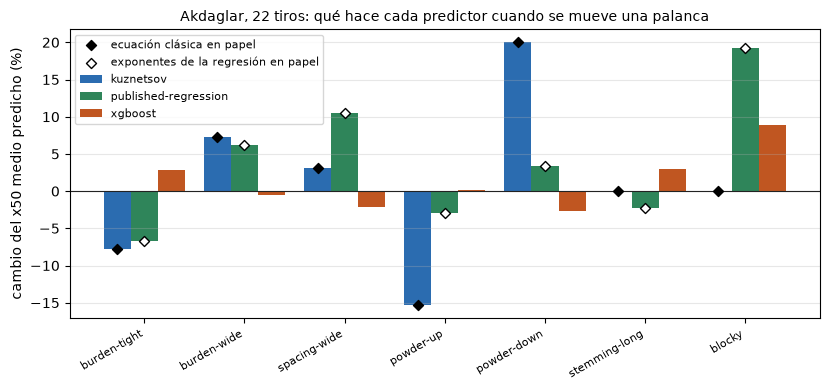

In [12]:
# Cambio del tamaño medio predicho por variante y predictor; rombos: los exponentes calculados en papel
colors = {"kuznetsov": "#2b6cb0", "published-regression": "#2f855a", "xgboost": "#c05621"}
x = np.arange(len(levers))
fig, ax = plt.subplots(figsize=(8.4, 4))
for k, name in enumerate(arms):
    ax.bar(x + (k - 1) * 0.27, change[name], 0.27, label=name, color=colors[name])
ax.scatter(x - 0.27, on_paper, marker="D", s=26, color="black", zorder=3, label="ecuación clásica en papel")
ax.scatter(x, regression_on_paper, marker="D", s=26, color="white", edgecolor="black", zorder=3,
    label="exponentes de la regresión en papel")
ax.axhline(0, color="#222", lw=0.8)
ax.set_xticks(x, levers, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("cambio del x50 medio predicho (%)")
ax.set_title("Akdaglar, 22 tiros: qué hace cada predictor cuando se mueve una palanca", fontsize=10)
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

**Qué muestra la figura.** Los rombos negros caen sobre las barras azules: la respuesta clásica es exactamente lo que dice la ecuación, por ejemplo -15,3 por ciento para el factor de carga mayor y +20,0 por ciento para el menor, y cero para el taco y los bloques, que la ecuación no contiene. Los rombos blancos también caen sobre las barras verdes: la respuesta de la regresión es su exponente ajustado, +10,5 por ciento para el espaciamiento mayor frente a +3,1 del clásico, y -2,2 por ciento para el taco mayor. Las barras naranjas, gradient boosting, no siguen a ninguno: +2,9 por ciento para un bordo más cerrado, +3,0 para el taco mayor y +8,9 para bloques mayores, y casi nada para el factor de carga. **Qué no muestra:** cuál respuesta es la correcta, porque ningún conjunto de datos registra una misma mina tronada dos veces con una palanca cambiada. **Qué se sigue:** las dos formas cerradas discrepan entre sí en el espaciamiento, el factor de carga y los bloques, y la aprendida no es función suave de ninguna palanca.

### Paso 4: lo que oculta la media de la campaña

La media sobre 22 tiros es un resumen, y para un modelo de árboles el resumen puede engañar. La celda predice cada uno de los 22 tiros bajo cada variante con gradient boosting, expresa el cambio de cada tiro como porcentaje y cuenta los tiros que no se mueven en absoluto.

In [13]:
# El cambio tiro a tiro para gradient boosting: cuántos tiros no se mueven en absoluto
boosting = arms["xgboost"]
base_sizes = [p.x50_m for p in boosting.predict(blasts)]
per_blast = {}
for vid in levers:
    moved = boosting.predict([apply_variant(blast, variants[vid]) for blast in blasts])
    per_blast[vid] = [100 * (p.x50_m / base - 1) for p, base in zip(moved, base_sizes)]
rows = [(vid, sum(abs(v) < 1e-9 for v in values), f"{min(values):+.1f}", f"{max(values):+.1f}") for vid,
    values in per_blast.items()]
Table(["variante", "tiros sin cambio (de 22)", "menor cambio (%)", "mayor cambio (%)"], rows)

| variante | tiros sin cambio (de 22) | menor cambio (%) | mayor cambio (%) |
|---|---|---|---|
| burden-tight | 7 | -4.8 | +11.9 |
| burden-wide | 6 | -6.8 | +8.3 |
| spacing-wide | 9 | -32.5 | +3.2 |
| powder-up | 15 | -4.3 | +2.6 |
| powder-down | 7 | -16.9 | +11.9 |
| stemming-long | 9 | -4.0 | +57.8 |
| blocky | 3 | -6.5 | +86.6 |

La celda siguiente dibuja el cambio tiro a tiro de gradient boosting para cada palanca, un punto por tiro, con el valor único de la ecuación clásica como rombo. Si el modelo fuera una función suave de la palanca, los puntos se apilarían a una misma altura; mire cómo se dispersan y cuántos quedan exactamente en cero.

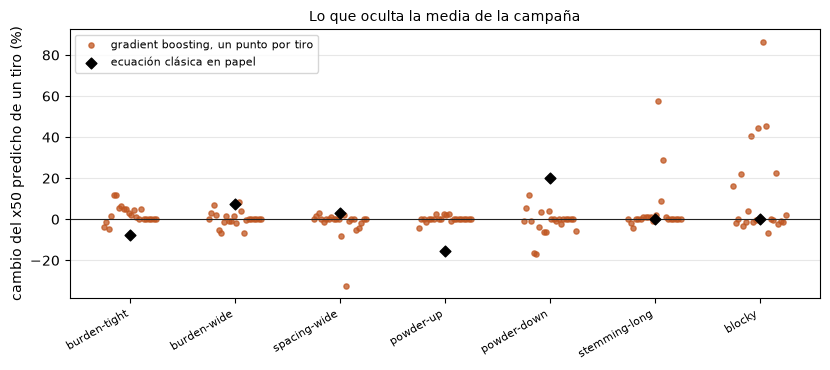

In [14]:
# El cambio de cada tiro bajo cada variante para gradient boosting; la ecuación clásica mueve todos los tiros por un
# mismo valor
fig, ax = plt.subplots(figsize=(8.4, 3.8))
for k, vid in enumerate(levers):
    ax.scatter(np.full(len(blasts), k) + np.linspace(-0.25, 0.25, len(blasts)), per_blast[vid], s=14, color="#c05621",
        alpha=0.75,
               label="gradient boosting, un punto por tiro" if k == 0 else None)
ax.scatter(x, on_paper, marker="D", s=30, color="black", zorder=3, label="ecuación clásica en papel")
ax.axhline(0, color="#222", lw=0.8)
ax.set_xticks(x, levers, rotation=30, ha="right", fontsize=8)
ax.set_ylabel("cambio del x50 predicho de un tiro (%)")
ax.set_title("Lo que oculta la media de la campaña", fontsize=10)
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

**Qué muestra la figura.** Un conjunto de árboles es constante por tramos, así que un tiro que se queda dentro de su hoja no se mueve: con el factor de carga mayor 15 de los 22 tiros conservan exactamente su predicción base, y con el menor 7. Un tiro que cruza una división salta: un taco mayor mueve un tiro en +57,8 por ciento y bloques mayores mueven uno en +86,6 por ciento, frente a una media de campaña de +3,0 y +8,9 por ciento. Los rombos negros, la ecuación clásica, mueven todos los tiros en la misma cantidad. **Qué no muestra:** que los saltos sean errados, solo que no responden a un cambio pequeño sino a un umbral de los datos de entrenamiento. **Qué se sigue:** una vista de diseño construida sobre un predictor aprendido debería mostrar tiro a tiro, no solo la media.

## Resultados

**Respuesta:** la ecuación clásica responde a las tres palancas que contiene y a nada más, la regresión publicada a toda entrada que tiene, con exponentes que ajustó, y gradient boosting a otro conjunto de palancas y a saltos. La ecuación clásica se mueve -7,8 por ciento con el bordo más cerrado, +3,1 con el espaciamiento mayor, -15,3 con el factor de carga mayor y +20,0 con el menor, y exactamente 0,0 con el taco mayor y los bloques mayores. La regresión sigue sus exponentes (-6,7, +10,5, -3,0, +3,4, y -2,2 y +19,2 para las dos palancas que la ecuación ignora). Gradient boosting se mueve +2,9 por ciento cuando se cierra el bordo y +0,1 cuando se sube el factor de carga, y 15 de los 22 tiros no se mueven con esa variante.

Las dos formas cerradas son exactas a su papel: la tabla del paso 3 muestra el motor y los exponentes coincidiendo hasta una décima de por ciento en cada fila, así que la respuesta es la aritmética de la ecuación y no un artefacto. Discrepan sobre el mundo: la ecuación clásica hace del factor de carga su palanca más fuerte y la regresión una de las más débiles; la regresión hace de los bloques la más fuerte, y la ecuación los ignora.

**Qué no muestra esto.** Son respuestas de modelos, no de voladuras. El corpus contiene tiros distintos en minas distintas, así que un exponente ajustado refleja cómo difieren los tiros entre minas, no lo que ocurre al girar una palanca en un tiro. El producto por eso rotula estas curvas como la respuesta del modelo y nunca como un pronóstico.

## Resumen

- Una variante mueve un campo de un tiro por un multiplicador, descarta la medición y predice de nuevo; la respuesta de un predictor es la media sobre los 22 tiros de la campaña.
- La respuesta clásica puede calcularse en papel (`B^(1/2)`, `S^(1/6)`, `Pf^(-19/30)`, nada para el taco y los bloques) y el motor la reproduce; la respuesta de la regresión es su exponente ajustado.
- Gradient boosting responde a saltos: 15 de 22 tiros no se mueven con el factor de carga mayor, y tiros individuales saltan hasta +86,6 por ciento.
- Siguiente: el notebook 02 barre dos palancas a la vez, el bordo y el espaciamiento, y compara las tres superficies.

## Referencias

- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus y la regresión publicada)
- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (regresión de vectores de soporte, núcleo rbf; la ecuación clásica)
- Sui, Zhou, Zhao, Yang y Zou 2025, https://doi.org/10.3390/app15031254 (vectores de soporte polinómico, bosque, boosting, apilamiento)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/